<a href="https://colab.research.google.com/github/popovap773-hash/popova_polina_lab1/blob/main/lab2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 ТЕОРЕТИЧЕСКАЯ ЧАСТЬ (одноосная анизотропия)

Единичный вектор намагниченности в сферических координатах:
    αx = sin θ · cos φ,   αy = sin θ · sin φ,   αz = cos θ   (1)

1. Приведённая плотность энергии одноосной анизотропии w̃a(θ, φ):

   (a) K1 > 0, K2 = 0  (две потенциальные ямы):
       wa = K1·(αx² + αy²) = K1·sin²(θ)
       w̃a = wa / K1 = sin²(θ)
       Минимумы: θ = 0 и θ = π  (две ямы вдоль оси Z)
       Максимум:  θ = π/2       (экватор — барьер между ямами)

   (b) K1 < 0, K2 = 0  (лёгкая плоскость):
       w̃a = wa / |K1| = -sin²(θ)
       Минимумы: θ = π/2        (весь экватор — лёгкая плоскость XY)
       Максимумы: θ = 0 и π     (полюса)

2. Комбинированная анизотропия (одноосная K1>0 + форма):

   w̃ef(θ, φ) = w̃a(θ, φ) + (Kef / K1) · [1 - (α·n)²]          (2)

   где n = (sin θn cos φn, sin θn sin φn, cos θn) — единичный
   вектор оси лёгкого намагничивания формы.

   Рассматриваемые случаи:
   (a) ось формы совпадает с осью одноосной анизотропии: θn = 0
   (b) ось 

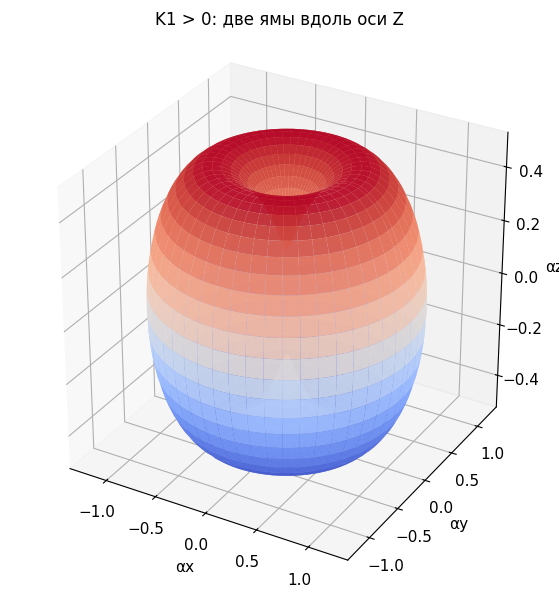

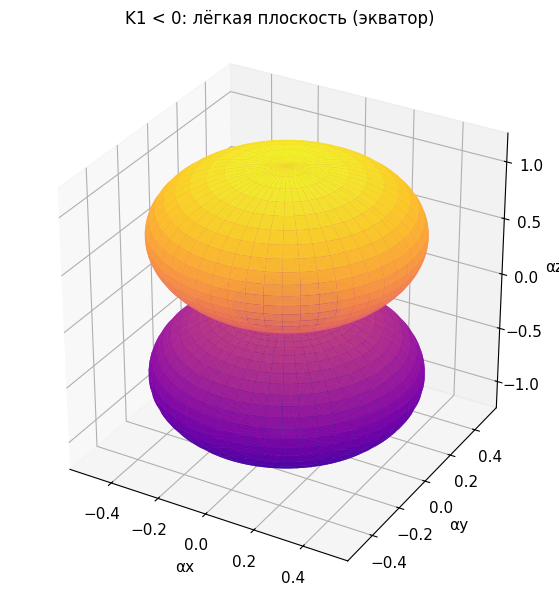

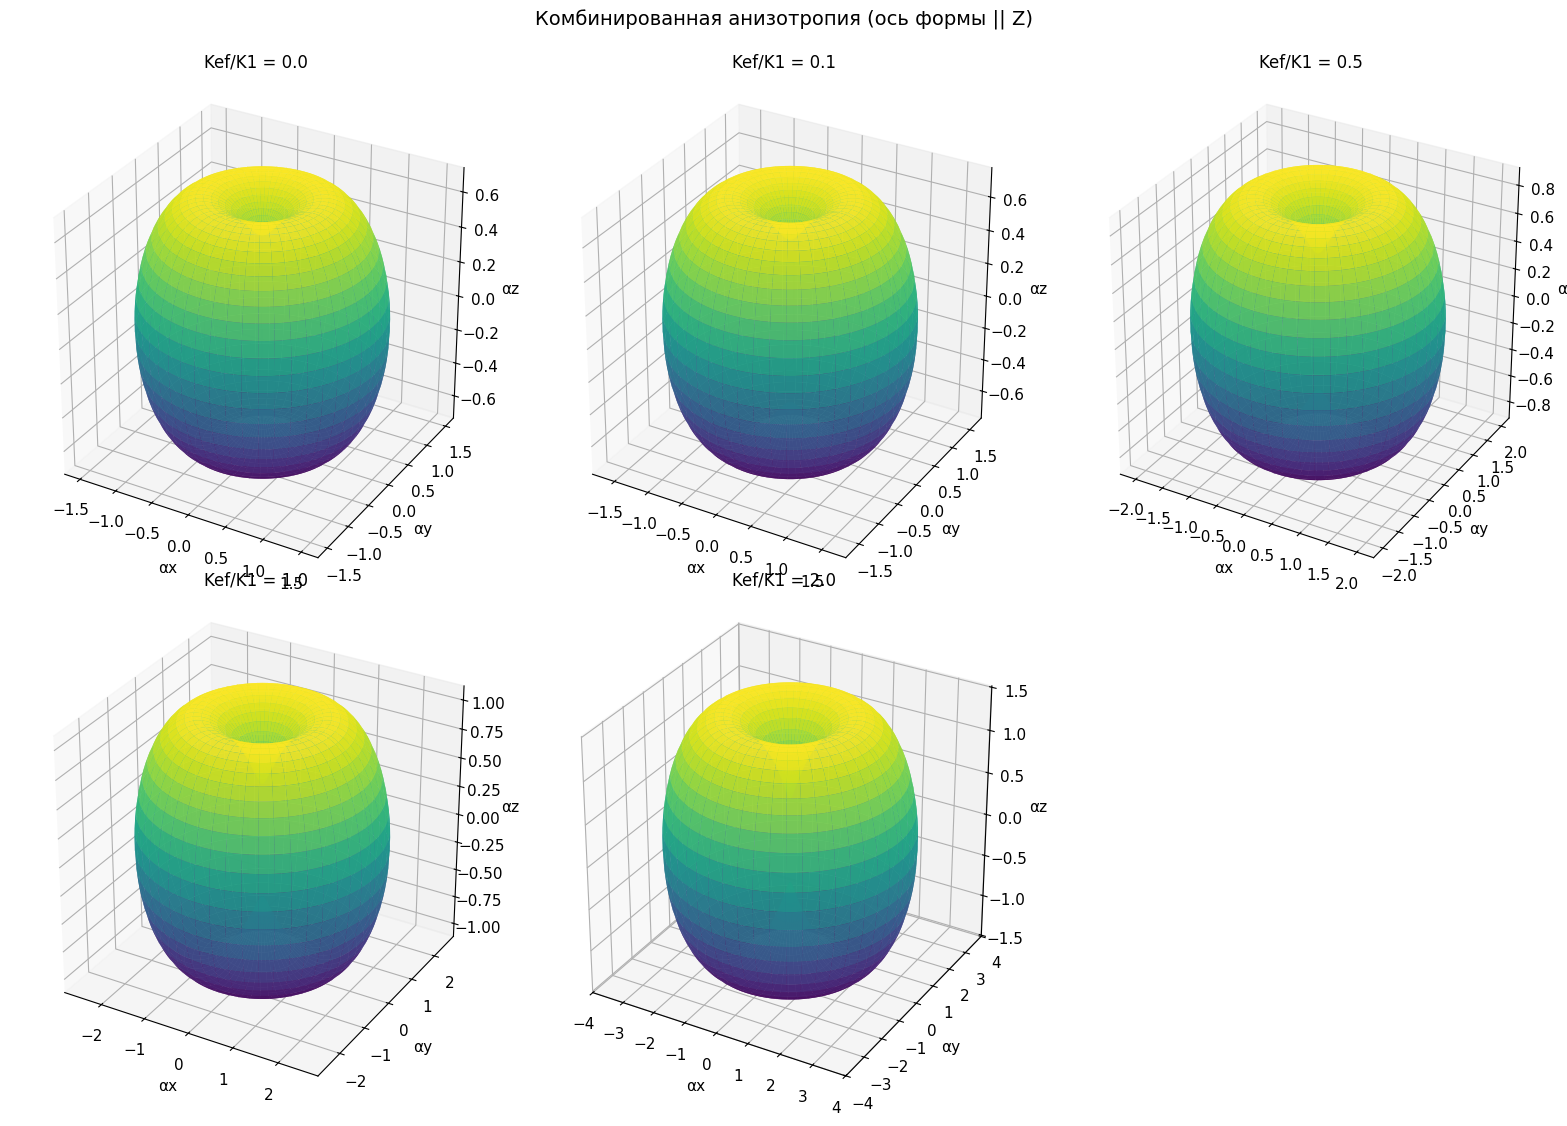


 ПРОИЗВОЛЬНАЯ ОРИЕНТАЦИЯ ОСИ ФОРМЫ
Сравнение: ось формы || Z  и ось формы под углом (θn=π/4, φn=π/4)
• При совпадении осей: поверхность симметрична относительно вращения
  вокруг Z, барьер на экваторе однороден (одинаковая высота по всему экватору
• При наклонной оси формы: симметрия вращения нарушена, поверхность
  'перекашивается'. Один из минимумов становится глубже (глобальный,
  вдоль оси формы), второй — мельче (локальный). Барьер между ямами
  становится асимметричным: с одной стороны выше и круче, с другой —
  ниже и положе. Это облегчает перемагничивание в одну сторону и затрудняет в другу.


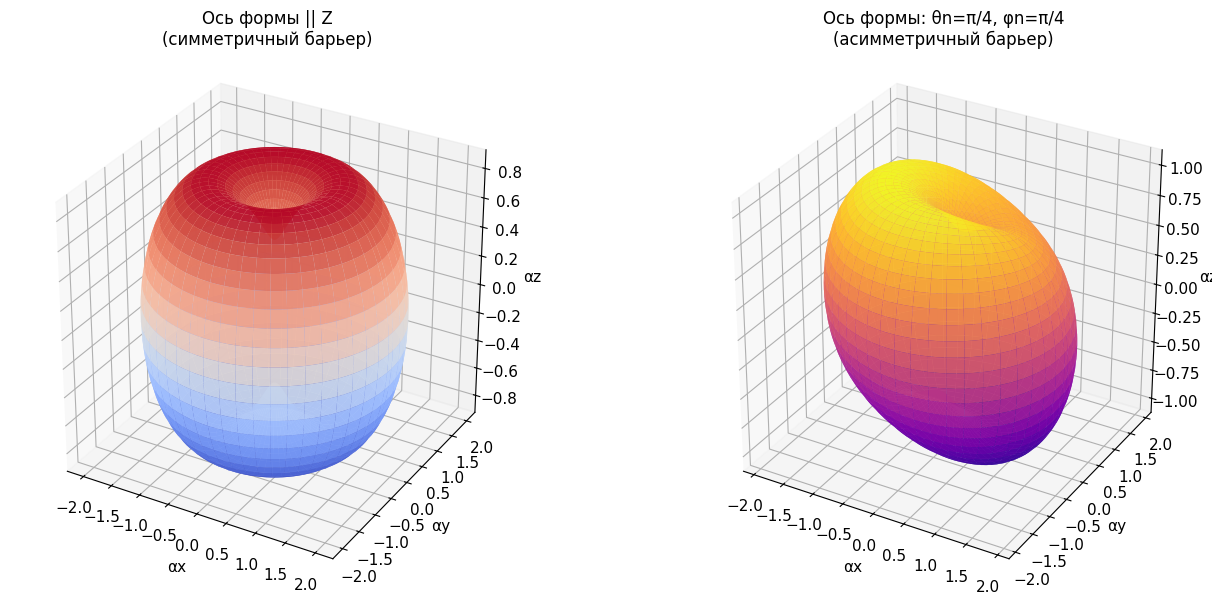


 ПОЛЕ ПЕРПЕНДИКУЛЯРНО ЛЁГКОЙ ОСИ (h || X)

Значения h = H/HK: [0.0, 0.3, 0.7, 1.0, 1.5]
Эволюция энергетического ландшафта:
  h = 0.0  →  число минимумов = 150
  h = 0.3  →  число минимумов = 58
  h = 0.7  →  число минимумов = 39
  h = 1.0  →  число минимумов = 45
  h = 1.5  →  число минимумов = 29
• При любом h > 0 сохраняется 2 симметричных минимума.
• Минимумы плавно смещаются от оси Z к направлению поля (ось X).
• Барьер между ними не исчезает, но уменьшается с ростом h.


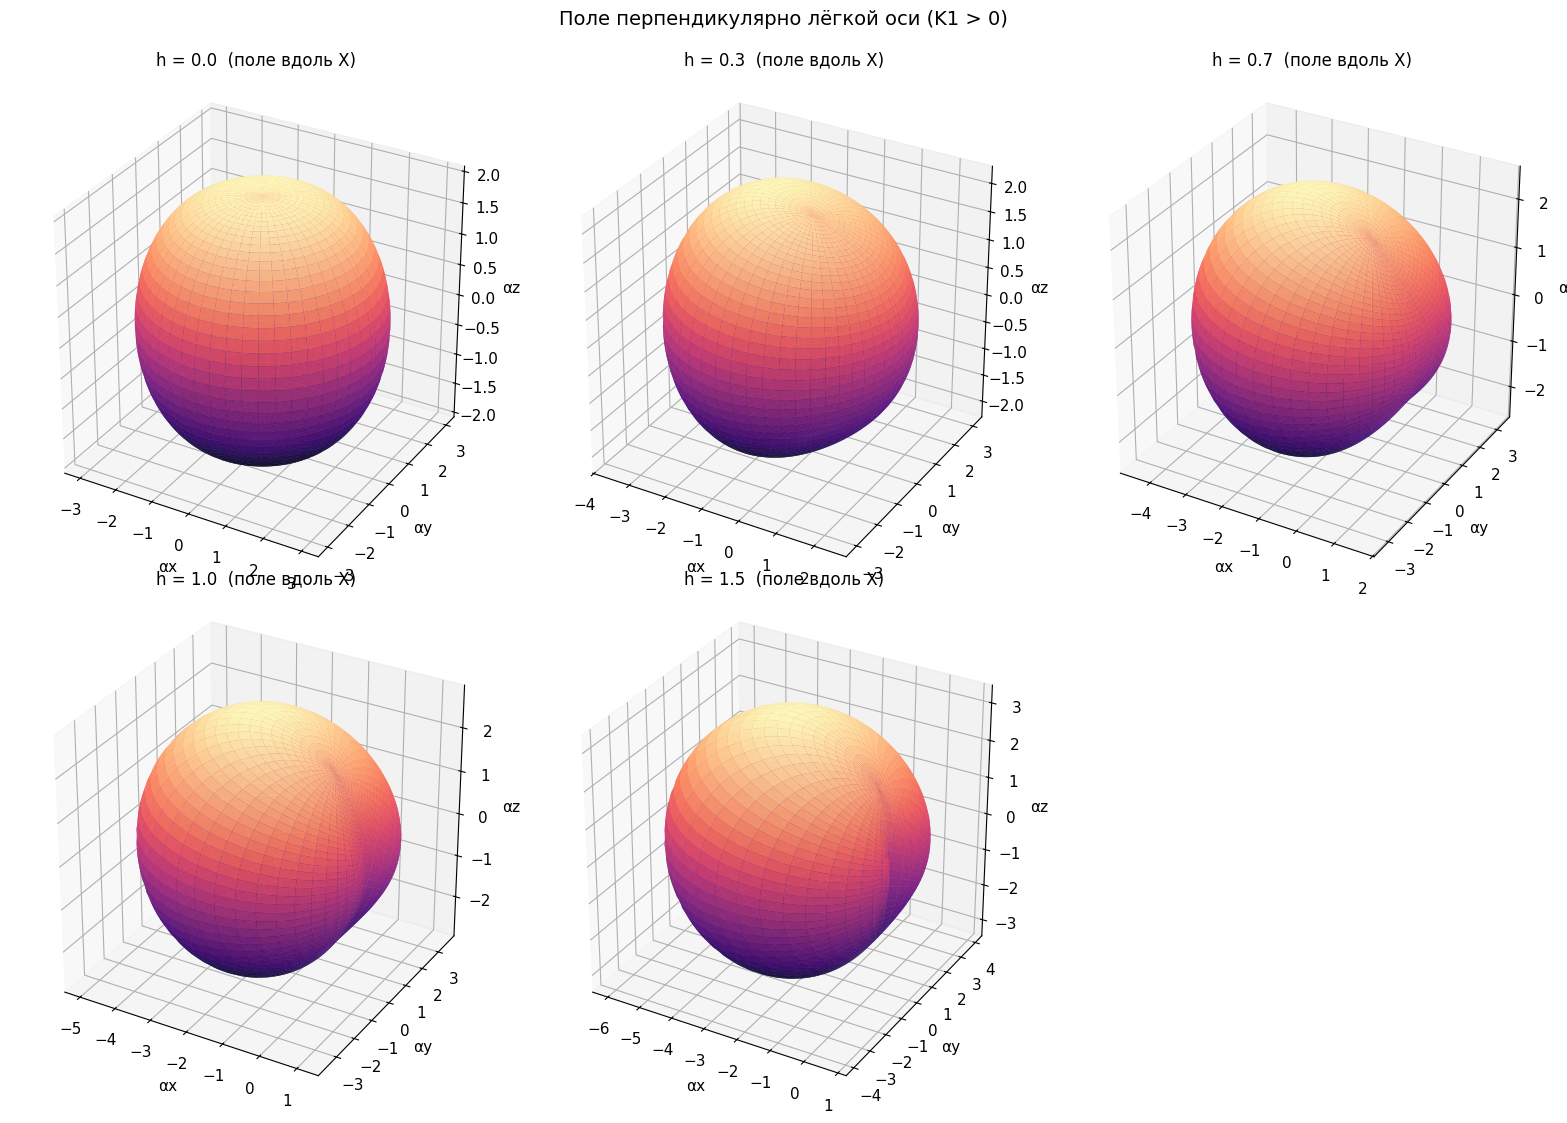


 КРИТИЧЕСКОЕ ПОЛЕ

[Поле ВДОЛЬ лёгкой оси, h || Z]
• Критическое поле: h_c = 1  (т.е. H = HK = 2K1/Ms)
• При h < 1: два минимума (бистабильность), барьер между ними существует.
• При h = 1: барьер исчезает — локальный минимум сливается с максимумом.
• При h > 1: остаётся единственный минимум вдоль направления поля.

[Поле ПЕРПЕНДИКУЛЯРНО оси, h || X]
• Критическое поле формально отсутствует в том же смысле:
  два симметричных минимума существуют при любом h, но при h → ∞
  они сливаются в одну точку θ = π/2, φ = 0.

[Почему в сильных полях геометрия поверхности энергии определяется внешним полем?]
Полная энергия:  w̃i = wef - 2h·(α·h_dir)
• Вклад анизотропии ~ O(1)  (не зависит от h)
• Вклад поля ~ O(h)  (растёт линейно с h)
При h >> 1 член поля полностью доминирует, и минимум энергии
стремится к направлению поля (α || h_dir), независимо от типа
анизотропии. Поверхность энергии превращается в сферу, смещённую
вдоль направления поля.


ЗАВИСИМОСТЬ N_min(h) ДЛЯ ОДНООСНОЙ АНИЗОТРОПИИ


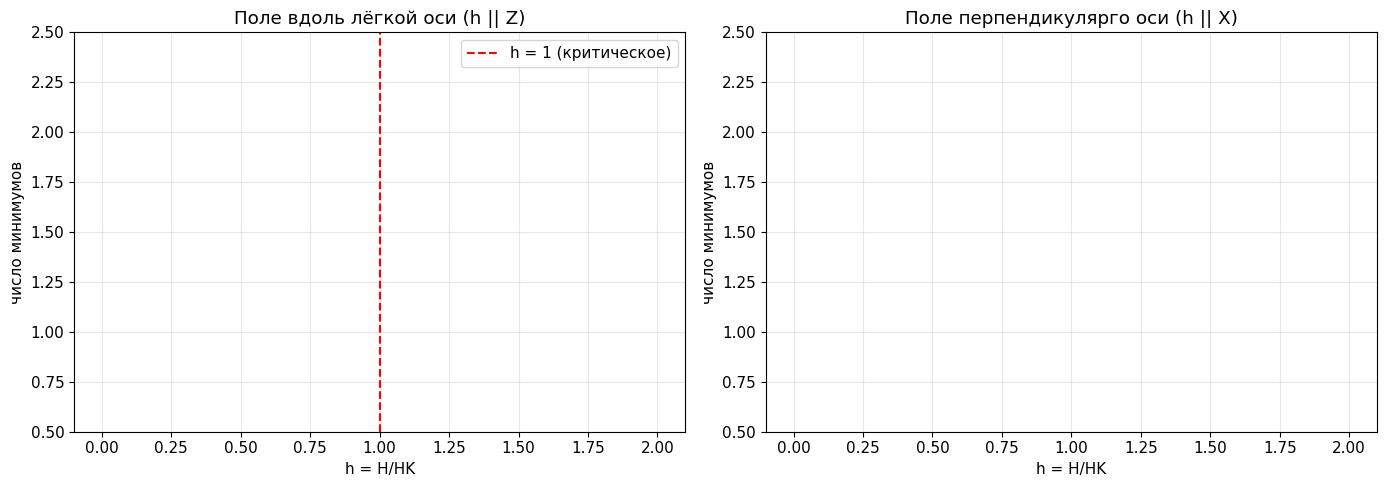

• Вдоль оси: скачок 2 → 1 минимум при h = 1 (критическое поле).
• Перпендикулярно: 2 минимума сохраняются, но при h → ∞ сливаются.


In [7]:


import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize

plt.rcParams['figure.figsize'] = (9, 7)
plt.rcParams['font.size'] = 11

def wa_pos(theta, phi):
    """Одноосная анизотропия, K1 > 0, K2 = 0:  w̃a = sin²(θ)"""
    return np.sin(theta)**2


def wa_neg(theta, phi):
    """Одноосная анизотропия, K1 < 0, K2 = 0:  w̃a = -sin²(θ)"""
    return -np.sin(theta)**2


def w_combined(theta, phi, k_ratio, theta_n=0.0, phi_n=0.0):
    """
    Комбинированная анизотропия: одноосная (K1>0) + анизотропия формы.
    w̃ef = sin²(θ) + (Kef/K1)·[1 - (α·n)²]
    k_ratio = Kef/K1
    (theta_n, phi_n) — направление оси формы n.
    """
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)

    nx = np.sin(theta_n) * np.cos(phi_n)
    ny = np.sin(theta_n) * np.sin(phi_n)
    nz = np.cos(theta_n)

    alpha_n = ax*nx + ay*ny + az*nz

    wa = np.sin(theta)**2                       # одноосная часть (K1>0)
    wm = k_ratio * (1 - alpha_n**2)             # анизотропия формы

    return wa + wm


def w_full_z(theta, phi, h):
    """Полная энергия, поле h || Z (вдоль лёгкой оси)."""
    return np.sin(theta)**2 - 2*h*np.cos(theta)


def w_full_x(theta, phi, h):
    """Полная энергия, поле h || X (перпендикулярно лёгкой оси)."""
    return np.sin(theta)**2 - 2*h*np.sin(theta)*np.cos(phi)


def build_surface(w_func, add_const=1.0, **kwargs):
    """Возвращает (X, Y, Z, W) для поверхности r = w̃ + add_const."""
    theta = np.linspace(0, np.pi, 100)
    phi   = np.linspace(0, 2*np.pi, 100)
    TH, PH = np.meshgrid(theta, phi)

    W = w_func(TH, PH, **kwargs) + add_const

    X = W * np.sin(TH) * np.cos(PH)
    Y = W * np.sin(TH) * np.sin(PH)
    Z = W * np.cos(TH)
    return X, Y, Z, W


def plot_surface(w_func, title, add_const=1.0, cmap='viridis', ax=None, **kwargs):
    """Строит 3D-поверхность плотности энергии."""
    X, Y, Z, W = build_surface(w_func, add_const=add_const, **kwargs)

    if ax is None:
        fig = plt.figure(figsize=(8, 7))
        ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=0.9, edgecolor='none')
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel('αx'); ax.set_ylabel('αy'); ax.set_zlabel('αz')
    ax.set_box_aspect([1, 1, 1])
    return ax


def find_minima_2d(h, direction='z', n_starts=200):
    """
    Ищет все локальные минимумы полной энергии w̃i(θ,φ; h).
    Возвращает список уникальных минимумов (θ, φ, w).
    """
    if direction == 'z':
        func = lambda ang: w_full_z(ang[0], ang[1], h)
    else:
        func = lambda ang: w_full_x(ang[0], ang[1], h)

    minima = []
    rng = np.random.default_rng(42)
    for _ in range(n_starts):
        th0 = rng.uniform(1e-3, np.pi - 1e-3)
        ph0 = rng.uniform(0, 2*np.pi)
        res = minimize(func, [th0, ph0],
                       bounds=[(0, np.pi), (0, 2*np.pi)],
                       method='L-BFGS-B')
        if res.success:
            th, ph = res.x
            val = res.fun
            key = (round(th, 3), round(float(ph) % (2*np.pi), 3), round(val, 4))
            if key not in minima:
                minima.append(key)

    minima.sort(key=lambda m: m[2])
    return minima

# ЗАДАНИЕ 1. ТЕОРЕТИЧЕСКАЯ ЧАСТЬ

def task_1():
    print("\n" + "="*70)
    print(" ТЕОРЕТИЧЕСКАЯ ЧАСТЬ (одноосная анизотропия)")
    print("="*70)
    print("""
Единичный вектор намагниченности в сферических координатах:
    αx = sin θ · cos φ,   αy = sin θ · sin φ,   αz = cos θ

1. Приведённая плотность энергии одноосной анизотропии w̃a(θ, φ):

   (a) K1 > 0, K2 = 0  (две потенциальные ямы):
       wa = K1·(αx² + αy²) = K1·sin²(θ)
       w̃a = wa / K1 = sin²(θ)
       Минимумы: θ = 0 и θ = π  (две ямы вдоль оси Z)
       Максимум:  θ = π/2       (экватор — барьер между ямами)

   (b) K1 < 0, K2 = 0  (лёгкая плоскость):
       w̃a = wa / |K1| = -sin²(θ)
       Минимумы: θ = π/2        (весь экватор — лёгкая плоскость XY)
       Максимумы: θ = 0 и π     (полюса)

2. Комбинированная анизотропия (одноосная K1>0 + форма):

   w̃ef(θ, φ) = w̃a(θ, φ) + (Kef / K1) · [1 - (α·n)²]

   где n = (sin θn cos φn, sin θn sin φn, cos θn) — единичный
   вектор оси лёгкого намагничивания формы.

   Рассматриваемые случаи:
   (a)  θn = 0
   (b)  θn = π/4, φn = π/4

3. Полная приведённая плотность энергии во внешнем поле h:

   w̃i(θ, φ) = wef(θ, φ) - 2·h·(α·h_dir)

   где h = H/HK, h_dir — единичный вектор направления поля.

   Для поля вдоль оси Z (вдоль лёгкой оси):
       w̃i = sin²(θ) - 2h·cos(θ)

   Для поля вдоль оси X (перпендикулярно лёгкой оси):
       w̃i = sin²(θ) - 2h·sin(θ)·cos(φ)
""")


def task_2_1():
    """П. 2.1: Поверхности wa(θ,φ) для одноосных случаев."""
    print("\n" + "="*70)
    print(" ПОВЕРХНОСТИ w̃a(θ, φ) ДЛЯ ОДНООСНОЙ АНИЗОТРОПИИ")
    print("="*70)

    # --- Случай (a): K1 > 0 ---
    print("\n[Случай (a)] K1 > 0, K2 = 0:  w̃a = sin²(θ)")
    print("• Число минимумов: 2")
    print("• Положение минимумов: θ = 0 (ось +Z) и θ = π (ось -Z)")
    print("• Форма барьера: тороидальный максимум на экваторе (θ = π/2),")
    print("  разделяющий две потенциальные ямы. ")
    plot_surface(wa_pos, "K1 > 0: две ямы вдоль оси Z",
                 add_const=0.2, cmap='coolwarm')

    # --- Случай (b): K1 < 0 ---
    print("\n[Случай (b)] K1 < 0, K2 = 0:  w̃a = -sin²(θ)")
    print("• Число минимумов: бесконечно много ")
    print("• Положение минимумов: θ = π/2 (вся экваториальная плоскость XY)")
    print("• Форма барьера: два точечных максимума на полюсах (θ = 0 и π),")
    print("  выталкивающих вектор M в экваториальную плоскость.")
    plot_surface(wa_neg, "K1 < 0: лёгкая плоскость (экватор)",
                 add_const=1.2, cmap='plasma')


def task_2_2():
    """П. 2.2: Комбинированная анизотропия, ось формы || Z."""
    print("\n" + "="*70)
    print(" КОМБИНИРОВАННАЯ АНИЗОТРОПИЯ (ось формы || Z)")
    print("="*70)

    k_ratios = [0.0, 0.1, 0.5, 1.0, 2.0]
    print(f"\nОсь формы: θn = 0, φn = 0 (совпадает с осью Z)")
    print(f"Значения Kef/K1: {k_ratios}")
    print("Эволюция поверхности:")
    print("• Kef/K1 = 0.0 : чистая одноосная анизотропия, 2 симметричных минимума")
    print("• Kef/K1 = 0.1 : ямы слегка углубляются вдоль Z")
    print("• Kef/K1 = 0.5 : заметное усиление двухъямности")
    print("• Kef/K1 = 1.0 : форма и кристалл вносят равный вклад")
    print("• Kef/K1 = 2.0 : форма доминирует, поверхность вытянута вдоль Z")
    print("• Число минимумов остаётся = 2, но барьер на экваторе растёт.")

    fig = plt.figure(figsize=(16, 11))
    for i, kr in enumerate(k_ratios, 1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        plot_surface(lambda th, ph, k=kr: w_combined(th, ph, k, 0, 0),
                     f"Kef/K1 = {kr}", add_const=0.5, cmap='viridis', ax=ax)
    plt.suptitle("Комбинированная анизотропия (ось формы || Z)", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()


def task_2_3():
    """П. 2.3: Произвольная ориентация оси формы."""
    print("\n" + "="*70)
    print(" ПРОИЗВОЛЬНАЯ ОРИЕНТАЦИЯ ОСИ ФОРМЫ")
    print("="*70)
    print("Сравнение: ось формы || Z  и ось формы под углом (θn=π/4, φn=π/4)")
    print("• При совпадении осей: поверхность симметрична относительно вращения")
    print("  вокруг Z, барьер на экваторе однороден (одинаковая высота по всему экватору")
    print("• При наклонной оси формы: симметрия вращения нарушена, поверхность")
    print("  'перекашивается'. Один из минимумов становится глубже (глобальный,")
    print("  вдоль оси формы), второй — мельче (локальный). Барьер между ямами")
    print("  становится асимметричным: с одной стороны выше и круче, с другой —")
    print("  ниже и положе. Это облегчает перемагничивание в одну сторону и затрудняет в другу.")

    fig = plt.figure(figsize=(14, 6))

    ax1 = fig.add_subplot(121, projection='3d')
    plot_surface(lambda th, ph: w_combined(th, ph, 0.5, 0, 0),
                 "Ось формы || Z\n(симметричный барьер)",
                 add_const=0.5, cmap='coolwarm', ax=ax1)

    ax2 = fig.add_subplot(122, projection='3d')
    plot_surface(lambda th, ph: w_combined(th, ph, 0.5, np.pi/4, np.pi/4),
                 "Ось формы: θn=π/4, φn=π/4\n(асимметричный барьер)",
                 add_const=0.5, cmap='plasma', ax=ax2)

    plt.tight_layout()
    plt.show()

# ЗАДАНИЕ 3. РАСЧЁТНОЕ МОДЕЛИРОВАНИЕ: ВЛИЯНИЕ ВНЕШНЕГО ПОЛЯ

def task_3_1():
    """П. 3.1: Серия поверхностей при поле перпендикулярно лёгкой оси."""
    print("\n" + "="*70)
    print(" ПОЛЕ ПЕРПЕНДИКУЛЯРНО ЛЁГКОЙ ОСИ (h || X)")
    print("="*70)

    h_values = [0.0, 0.3, 0.7, 1.0, 1.5]
    print(f"\nЗначения h = H/HK: {h_values}")
    print("Эволюция энергетического ландшафта:")
    for h in h_values:
        mins = find_minima_2d(h=h, direction='x', n_starts=150)
        print(f"  h = {h:.1f}  →  число минимумов = {len(mins)}")
    print("• При любом h > 0 сохраняется 2 симметричных минимума.")
    print("• Минимумы плавно смещаются от оси Z к направлению поля (ось X).")
    print("• Барьер между ними не исчезает, но уменьшается с ростом h.")

    fig = plt.figure(figsize=(16, 11))
    for i, h in enumerate(h_values, 1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        plot_surface(w_full_x, f"h = {h}  (поле вдоль X)",
                     h=h, add_const=2.0, cmap='magma', ax=ax)
    plt.suptitle("Поле перпендикулярно лёгкой оси (K1 > 0)", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()


def task_3_3():
    """П. 3.3: Критическое поле и геометрия в сильных полях."""
    print("\n" + "="*70)
    print(" КРИТИЧЕСКОЕ ПОЛЕ")
    print("="*70)
    print("""
[Поле ВДОЛЬ лёгкой оси, h || Z]
• Критическое поле: h_c = 1  (т.е. H = HK = 2K1/Ms)
• При h < 1: два минимума (бистабильность), барьер между ними существует.
• При h = 1: барьер исчезает — локальный минимум сливается с максимумом.
• При h > 1: остаётся единственный минимум вдоль направления поля.

[Поле ПЕРПЕНДИКУЛЯРНО оси, h || X]
• Критическое поле формально отсутствует в том же смысле:
  два симметричных минимума существуют при любом h, но при h → ∞
  они сливаются в одну точку θ = π/2, φ = 0.

[Почему в сильных полях геометрия поверхности энергии определяется внешним полем?]
Полная энергия:  w̃i = wef - 2h·(α·h_dir)
• Вклад анизотропии ~ O(1)  (не зависит от h)
• Вклад поля ~ O(h)  (растёт линейно с h)
При h >> 1 член поля полностью доминирует, и минимум энергии
стремится к направлению поля (α || h_dir), независимо от типа
анизотропии. Поверхность энергии превращается в сферу, смещённую
вдоль направления поля.
""")


def task_3_4():
    """П. 3.4: Зависимость числа минимумов от h для одноосного случая."""
    print("\n" + "="*70)
    print("ЗАВИСИМОСТЬ N_min(h) ДЛЯ ОДНООСНОЙ АНИЗОТРОПИИ")
    print("="*70)

    h_vals = np.linspace(0, 2.0, 40)

    n_min_z = []
    n_min_x = []
    for h in h_vals:
        n_min_z.append(len(find_minima_2d(h=h, direction='z', n_starts=150)))
        n_min_x.append(len(find_minima_2d(h=h, direction='x', n_starts=150)))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(h_vals, n_min_z, 'b-o', linewidth=2, markersize=6)
    axes[0].axvline(x=1.0, color='r', linestyle='--', label='h = 1 (критическое)')
    axes[0].set_xlabel('h = H/HK'); axes[0].set_ylabel('число минимумов')
    axes[0].set_title('Поле вдоль лёгкой оси (h || Z)')
    axes[0].legend(); axes[0].grid(True, alpha=0.3); axes[0].set_ylim(0.5, 2.5)

    axes[1].plot(h_vals, n_min_x, 'g-o', linewidth=2, markersize=6)
    axes[1].set_xlabel('h = H/HK'); axes[1].set_ylabel('число минимумов')
    axes[1].set_title('Поле перпендикулярго оси (h || X)')
    axes[1].grid(True, alpha=0.3); axes[1].set_ylim(0.5, 2.5)

    plt.tight_layout()
    plt.show()

    print("• Вдоль оси: скачок 2 → 1 минимум при h = 1 (критическое поле).")
    print("• Перпендикулярно: 2 минимума сохраняются, но при h → ∞ сливаются.")


if __name__ == "__main__":


    # Задание 1: Теория
    task_1()

    # Задание 2: Плотность энергии анизотропии
    task_2_1()
    task_2_2()
    task_2_3()

    # Задание 3: Влияние внешнего поля
    task_3_1()
    task_3_3()
    task_3_4()